# Hito 2: Análisis de coyuntura de la inflación en Chile

## 1. Introducción

Este análisis forma parte de nuestro proyecto Monitor de Coyuntura y Proyección de la Inflación en Chile, en el que buscamos estudiar cómo ha evolucionado la inflación en el país, enfocándonos en los componentes transables y no transables.

Para realizar nuestro estudio, utilizamos información del Banco Central de Chile y FRED. Dicha información fue guardada previamente en uan base de datos SQLite, asimismo cabe mencionar que los datos corresponden al período de enero de 2015 a julio de 2026.

En este hito, principalmente nos enfocamos en ver cómo ha cambiado la inflación durante el tiempo y cómo se han comportado algunas variables económicas que pueden tener relación con el comportamiento de la inflación. Para esto, se realizaron gráficos con el fin de comparar los datos y así entender mejor su comportamiento.

In [1]:
# Importar librerías necesarias
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Ubicamos la carpeta principal del proyecto
ruta_actual = Path.cwd()

if (ruta_actual / "data" / "coyuntura.db").exists():
    raiz = ruta_actual
else:
    raiz = ruta_actual.parent

# Ruta de nuestra base SQLite
ruta_db = raiz / "data" / "coyuntura.db"

# Verificamos que la base exista
if not ruta_db.exists():
    raise FileNotFoundError("No se encontró coyuntura.db")

# Nos conectamos a la base de datos
conexion = sqlite3.connect(ruta_db)

print("Conexión con SQLite realizada correctamente.")
print("Base de datos:", ruta_db)

Conexión con SQLite realizada correctamente.
Base de datos: c:\Users\catam\Downloads\kit-inicio-coyuntura (1)\kit-inicio-coyuntura\data\coyuntura.db


## 2. Evolución de la inflación interanual en Chile 

En esta parte veremos cómo cambia la inflación en Chile durante los períodos de enero de 2015 a julio de 2026. Para realizar esto, utilizaremos la serie de inflación interanual del Banco Central de Chile.

A partir de esa información, elaboramos un gráfico que nos permitirá observar los períodos en los que la inflación aumentó o disminuyó. Para comparar la evolución de la inflación, se añadió una línea de referencia del 3%, la cual corresponde a la meta de inflación puesta por el Banco Central.

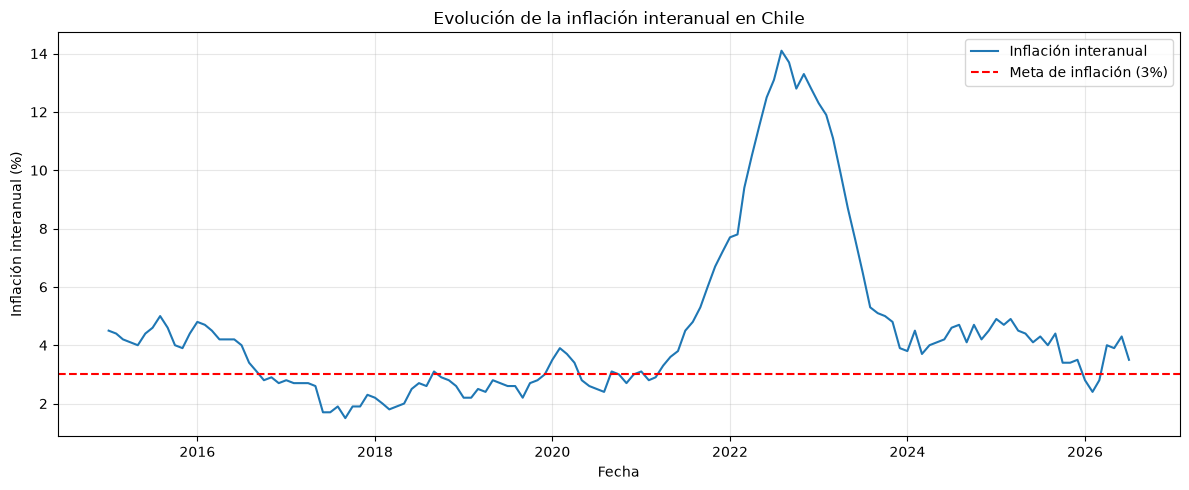

In [2]:
# Consulta de la inflación interanual
consulta_inflacion = """
SELECT o.fecha, o.valor AS inflacion_interanual
FROM observaciones o
JOIN series s ON o.id_serie = s.id_serie
WHERE s.id_serie = 'F074.IPC.V12.Z.EP23.C.M'
ORDER BY o.fecha;
"""

# Guardamos resultados
df_inflacion = pd.read_sql_query(consulta_inflacion, conexion)

# Pasamos fechas a formato Python
df_inflacion["fecha"] = pd.to_datetime(df_inflacion["fecha"])

# Creamos gráfico
plt.figure(figsize=(12, 5))

plt.plot(
df_inflacion["fecha"],
df_inflacion["inflacion_interanual"],
label="Inflación interanual")

# Línea de referencia de la meta de inflación del BC
plt.axhline(
y=3,
color="red",
linestyle="--",
label="Meta de inflación (3%)")

plt.title("Evolución de la inflación interanual en Chile")
plt.xlabel("Fecha")
plt.ylabel("Inflación interanual (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Interpretación de la evolución de la inflación en Chile

En el gráfico podemos ver que la inflación en Chile ha tenido varios cambios durante el período analizado, pero de manera general se mantuvo relativamente cerca de la meta del 3%.

Pese a esto, a partir del año 2021 se puede ver un aumento considerable de la inflación, llegando a valores cercanos al 14% durante el año 2022. Dicho aumento ocurrió en un período de mayores presiones inflacionarias tanto en Chile como a nivel internacional, sin embargo, con este gráfico no es posible determinar cuáles fueron los factores que tuvieron más influencia en su comportamiento.

Desde el año 2023, ya podemos observar que la inflación comienza a disminuir con respecto a los niveles alcanzados en el año 2022. Ya para los años 2024 y 2025 la inflación se mantuvo por encima del 3%, pero no llego a los niveles alcanzados en 2022.

Para el año 2026, la inflación interanual llegó al 3.5%, por lo que para ese entonces la inflación todavía se encontraba por encima de la meta del Banco Central. Con esto podemos ver que a pesar de que las presiones inflacionarias han disminuido de manera considerable, aún existen desafíos par alcanzar la meta.

## 3. Evolución de la inflación transable y no transable

En esta parte, veremos cómo ha evolucionado la inflación transable y no transable en el país. Esto nos será de utilidad para ver si ambos componentes presentan diferencias o un comportamiento similar durante los años estudiados. Para poder compararlos, calculamos la variación interanual de cada índice por medio de la función LAG().

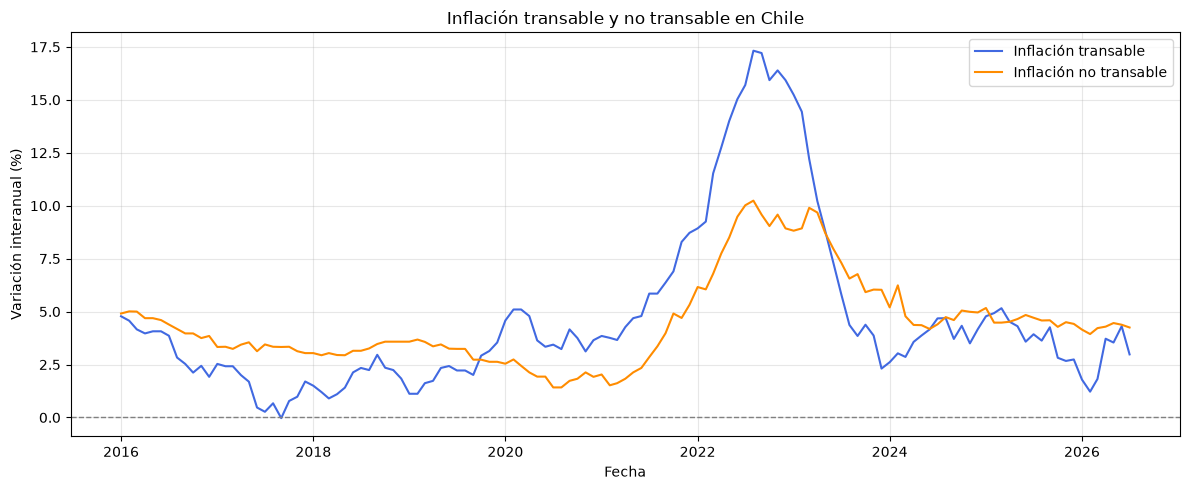

In [3]:
# Leemos las consultas desde nuestro archivo SQL
archivo_sql = raiz / "sql" / "04_consultas_inflacion.sql"

texto_sql = archivo_sql.read_text(encoding="utf-8")

# Separamos las tres consultas del archivo
consultas_sql = [consulta.strip()
    for consulta in texto_sql.split(";")
    if consulta.strip()]

# Utilizamos la tercera consulta: inflación transable y no transable
consulta_componentes = consultas_sql[2]

# Guardamos los resultados
df_componentes = pd.read_sql_query(consulta_componentes, conexion)

# Convertimos las fechas
df_componentes["fecha"] = pd.to_datetime(df_componentes["fecha"])

# Separaramos componentes
df_transables = df_componentes[df_componentes["indicador"].str.contains("transables", case=False)
& ~df_componentes["indicador"].str.contains("no transables", case=False)]

df_no_transables = df_componentes[df_componentes["indicador"].str.contains("no transables", case=False)]

# Creamos gráfico
plt.figure(figsize=(12, 5))

plt.plot(
df_transables["fecha"],
df_transables["inflacion_interanual"],
label="Inflación transable",
color="royalblue")

plt.plot(
df_no_transables["fecha"],
df_no_transables["inflacion_interanual"],
label="Inflación no transable",
color="darkorange")

plt.axhline(
y=0,
color="gray",
linestyle="--",
linewidth=1)

plt.title("Inflación transable y no transable en Chile")
plt.xlabel("Fecha")
plt.ylabel("Variación interanual (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Interpretación de la inflación transable y no transable

En el gráfico podemos ver que la inflación transable y no transable presentan comportamientos diferentes duranrte el período analizado.

Entre el año 2016 a 2020, la inflación no transable se mantuvo relativamente estable, mientras que la inflación no transable tuvo mayores fluctuaciones. Dicha diferencia puede estar relacionada con que los bienes que son transables están más expuestos a factores externos, como lo son el tipo de cambio o los precios internacionales.

Para el año 2021, tanto la inflación transable como la inflación no transable comenzaron a aumentar de manera considerable. Pese a esto, la que tuvo un mayor aumento fue la inflación transable, llegando a valores cercanos a 17%, mientras que la inflación no transable llegó al 10% aproximadamente.

Desde 2023, ambos componentes comenzaron a disminuir. La inflación transable disminuyó más rápido, mientras que la no transable presentó una disminución más lenta.

Esto también puede verse en julio de 2026, en donde podemos ver una diferencia de 1.27 puntos porcentuales, dado que la inflación transable logró registrar un 2.98% y la no transable un 4.25%.

En general, se puede observar que ambos componentes no evolucionaron de la misma manera, y que la inflación no transable ha disminuido más lentamente que la transable desde los niveles máximos alcanzados en 2022, lo que puede estar relacionado con factores internos.

## 4. Evolución del tipo de cambio y del precio del petróleo

En esta parte veremos cómo ha evolucionado el tipo de cambio observado y el precio internacional del petróleo Brent, dado que ambas variables pueden tener relación con el comportamiento de la inflación en Chile, en especial con el componente transable.

Para hacer esta comparación, utilizamos datos mensuales y calculamos la variación interanual de ambas variables.

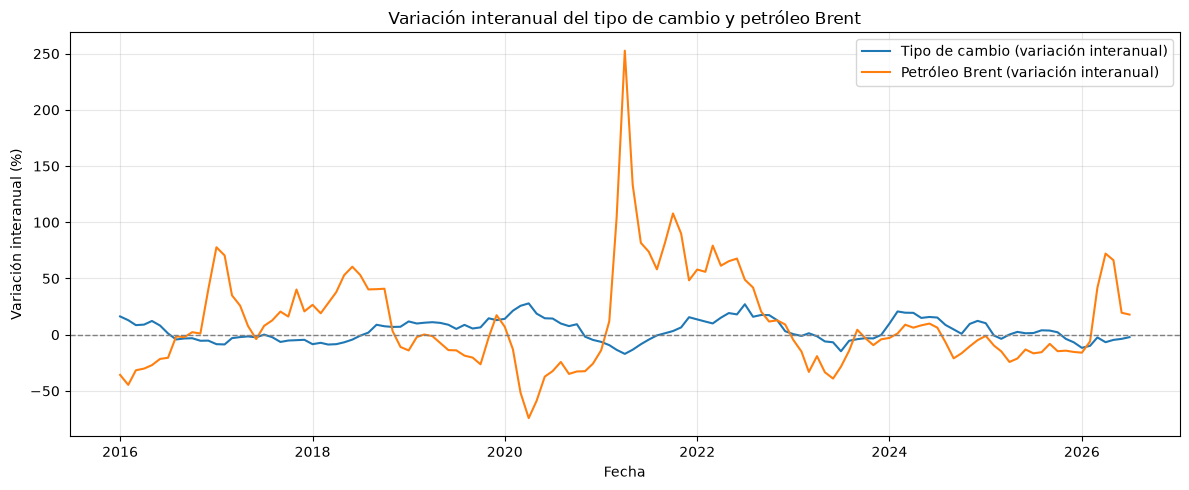

In [4]:
# Leemos las consultas desde nuestro archivo SQL
archivo_sql = raiz / "sql" / "04_consultas_inflacion.sql"
texto_sql = archivo_sql.read_text(encoding="utf-8")

# Separamos las consultas del archivo
consultas_sql = [consulta.strip()
    for consulta in texto_sql.split(";")
    if consulta.strip()]

# Utilizamos la cuarta consulta
consulta_externas = consultas_sql[3]

# Guardamos los resultados
df_externas = pd.read_sql_query(consulta_externas, conexion)

# Convertimos las fechas
df_externas["fecha"] = pd.to_datetime(df_externas["fecha"])

# Separamos las dos series
df_dolar_mensual = df_externas[df_externas["id_serie"] == "F073.TCO.PRE.Z.D"].copy()
df_petroleo_mensual = df_externas[df_externas["id_serie"] == "F019.PPB.PRE.41AB.M"].copy()


# Gráfico de ambas variaciones interanuales
plt.figure(figsize=(12, 5))

plt.plot(
df_dolar_mensual["fecha"],
df_dolar_mensual["variacion_anual"],
label="Tipo de cambio (variación interanual)")

plt.plot(
df_petroleo_mensual["fecha"],
df_petroleo_mensual["variacion_anual"],
label="Petróleo Brent (variación interanual)")

plt.axhline(
y=0,
color="gray",
linestyle="--",
linewidth=1)

plt.title("Variación interanual del tipo de cambio y petróleo Brent")
plt.xlabel("Fecha")
plt.ylabel("Variación interanual (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Interpretación del tipo de cambio y precio del petróleo

Al ver el gráfico podemos observar que tanto el tipo de cambio como el precio internacional del petróleo Brent presentan varios cambios durante el período analizado. Pese a esto, podemos ver que el petróleo tiene mayores fluctuaciones que el tipo de cambio, en especial durante los años 2020 y 2021.

En el año 2020, se puede ver una fuerte caída en el precio del petróleo, y seguido a esto un fuerte aumento durante 2021. Esto se puede relacionar con que estamos comparando los precios con los valores bajos del año anterior.

Durante los años 2021 y 2022, podemos ver aumentos en el precio del petróleo y en el tipo de cambio. Dichos cambios pueden afectar a la inflación, dado que cuando sube el dólar, los productos que son importados pueden volverse más caros. Por otro lado, el que el petróleo haya aumentado puede elvar los costos en el transporte y en la producción.

Ya en los años siguientes, se puede ver que ambas variables presentan cambios. Ya para el año 2026, podemos ver una aumento en la variación interanual del petróleo, mientras que el tipo de cambio presenta variaciones moderadas.

## 5. Evolución de la TPM y la inflación en Chile

En esta parte veremos cómo han evolucionado la Tasa de Política Monetaria (TPM) y la inflación en Chile durante los últimos años.

Para comparar ambas variables, utilizamos la inflación interanual y los datos de la TPM. Para ello, transformamos la TPM diaria a frecuencia mensual, por lo que utilizaremos el último valor disponible de cada mes.

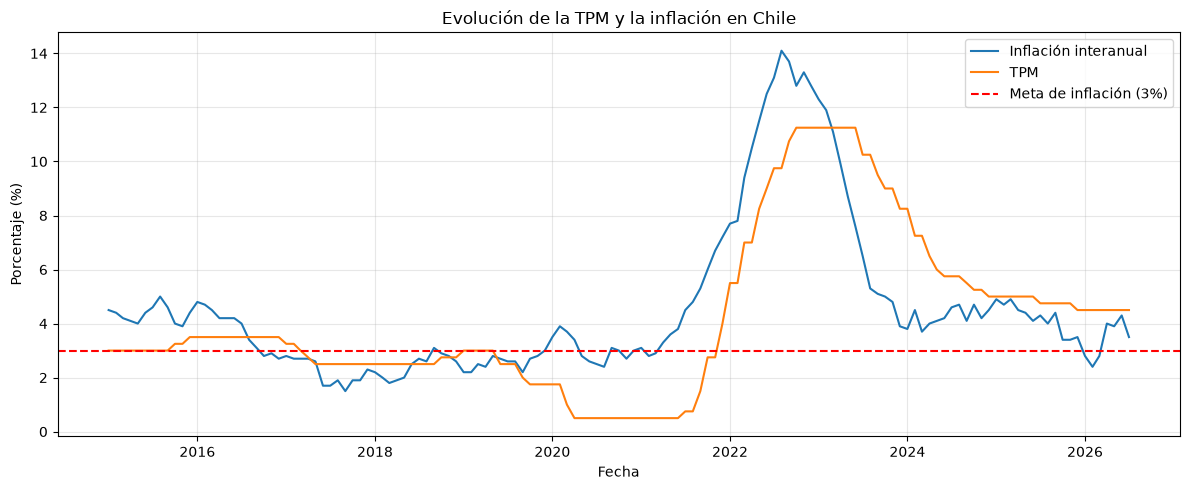

In [5]:
# Obtenenemos la TPM y la inflación
consulta_tpm = """
SELECT s.id_serie, o.fecha, o.valor
FROM observaciones o
JOIN series s ON o.id_serie = s.id_serie
WHERE s.id_serie IN ('F022.TPM.TIN.D001.NO.Z.D', 'F074.IPC.V12.Z.EP23.C.M')
ORDER BY o.fecha;
"""

df_tpm_inflacion = pd.read_sql_query(consulta_tpm, conexion)

# Convertimos fechas
df_tpm_inflacion["fecha"] = pd.to_datetime(df_tpm_inflacion["fecha"])

# Separaramos las dos series
df_tpm = df_tpm_inflacion[df_tpm_inflacion["id_serie"] == "F022.TPM.TIN.D001.NO.Z.D"].copy()
df_ipc = df_tpm_inflacion[df_tpm_inflacion["id_serie"] == "F074.IPC.V12.Z.EP23.C.M"].copy()

# Convertimos la TPM diaria a frecuencia mensual (utilizamos el último valor disponible de cada mes)
df_tpm["mes"] = df_tpm["fecha"].dt.to_period("M")

df_tpm_mensual = (df_tpm.sort_values("fecha").groupby("mes")["valor"].last().reset_index())

df_tpm_mensual["fecha"] = (df_tpm_mensual["mes"].dt.to_timestamp())

# Creamos gráfico
plt.figure(figsize=(12, 5))

plt.plot(
df_ipc["fecha"],
df_ipc["valor"],
label="Inflación interanual")

plt.plot(
df_tpm_mensual["fecha"],
df_tpm_mensual["valor"],
label="TPM")

plt.axhline(
y=3,
color="red",
linestyle="--",
label="Meta de inflación (3%)")

plt.title("Evolución de la TPM y la inflación en Chile")
plt.xlabel("Fecha")
plt.ylabel("Porcentaje (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Interpretación económica: TPM e inflación en Chile

Si vemos el gráfico podemos observar que la Tasa de Política Monetaria (TPM) y la inflación interanual en Chile han presentado ditintos cambios entre el año 2015 y julio de 2026.

Entre los años 2015 y 2019, ambas variables presentarons variaciones relativamente moderadas. Pese a esto, durante 2020 el Banco Central redujo la TPM hasta un 0.5% aproximadamente, dado a un contexto de pandemia y los efectos que trajó a la economía.

Para 2021, se puede ver que la inflación aumentó considerablemente, alcanzando niveles cercanos al 14% durante 2022. En ese período el Banco Central aumentó la TPM hasta llegar a un 11.25% aproximadamente, con el fin de disminuir la inflación y acercarla a la meta del 3%.

Desde 2023, la inflación comenzó a disminuir y posterior a eso el Banco Central fue reduciendo la TMP de manera gradual.

Ya para julio de 2026, la inflación interanual llegó al 3.5%, mientras que la TPM se encontraba alrededor del 4.5%.

Es importante recordar que los cambios en la TPM no afectan de manera inmediata a los precios, sino que los efectos que tenga pueden tardar varios meses, por lo que no es posible afirmar que toda la disminución de la inflación se debe solo a las decisiones que toma el Banco Central.

## 6. Evolución de la actividad económica en Chile

En esta parte analizaremos cómo ha evolucionado la actividad económica en Chile por medio del Índice Mensual de Actividad Económica (Imacec), el cual nos va a permitir obtener una idea de cómo se ha comportado la economía durante los últimos años.

Para esto, calculamos la variación interanual del Imacec, en donde comparamos el valor de cada mes con el mismo mes del año anterior, con el fin de ver los períodos en los que la actividad económica ha aumentado o disminuido.

Observaciones utilizadas: 127
         fecha      imacec  crecimiento_interanual
134 2026-03-01  120.374612                0.091624
135 2026-04-01  114.361518               -1.070156
136 2026-05-01  112.106264               -1.387179
137 2026-06-01  110.601447                2.015280
138 2026-07-01  106.967731               -1.487117


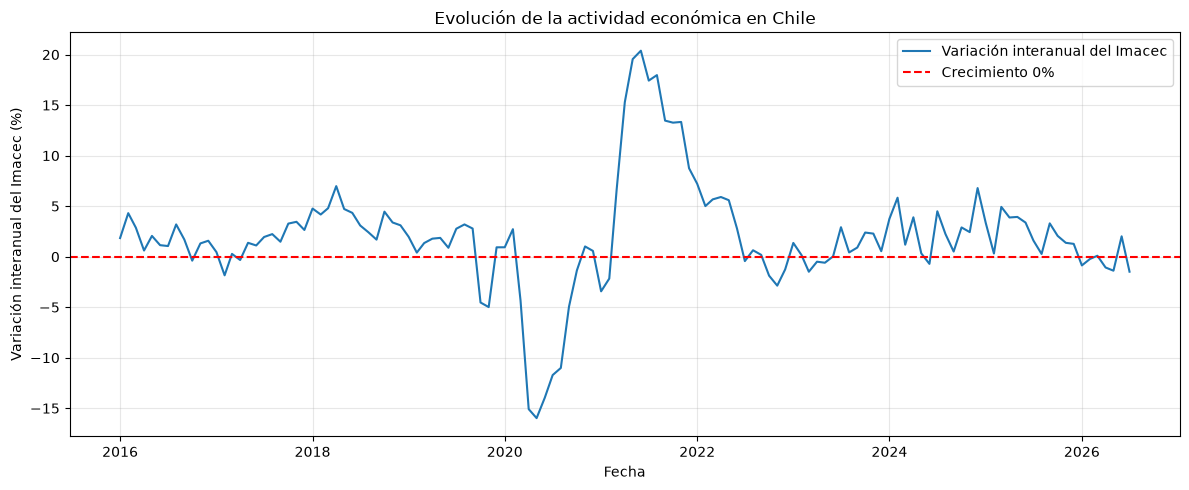

In [6]:
# Obtenemos Imacec
consulta_imacec = """
SELECT o.fecha, o.valor AS imacec
FROM observaciones o
JOIN series s ON o.id_serie = s.id_serie
WHERE s.id_serie = 'F032.IMC.IND.Z.Z.EP18.Z.Z.0.M'
ORDER BY o.fecha;
"""

# Guardamos datos
df_imacec = pd.read_sql_query(consulta_imacec, conexion)

# Convertimos fechas
df_imacec["fecha"] = pd.to_datetime(df_imacec["fecha"])

# Calculamos la variación interanual (12 meses)
df_imacec["crecimiento_interanual"] = (df_imacec["imacec"].pct_change(periods=12, fill_method=None) * 100)

# Eliminamos los meses sin variación calculable
df_imacec = df_imacec.dropna(subset=["crecimiento_interanual"])

# Mostramos la información para comprobar que los datos estén correctos
print("Observaciones utilizadas:", len(df_imacec))
print(df_imacec.tail())

# Creamos el gráfico
plt.figure(figsize=(12, 5))

plt.plot(
df_imacec["fecha"],
df_imacec["crecimiento_interanual"],
label="Variación interanual del Imacec")

plt.axhline(
y=0,
color="red",
linestyle="--",
label="Crecimiento 0%")

plt.title("Evolución de la actividad económica en Chile")
plt.xlabel("Fecha")
plt.ylabel("Variación interanual del Imacec (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()


### Interpretación de la evolución del Imacec

Si vemos el gráfico podemos observar que la actividad económica en Chile ha presentado varios cambios entre 2016 y julio de 2026.

Durante los primeros años, el Imacec registró inicialmente variaciones positivas, pero hubo algunos meses en que la actividad económica disminuyó. En el año 2020, podemos ver una importante caída, en donde llegó a valores cercanos al 15%, cosa que ocurrió en un contexto de pandemia.

Luego, durante el año 2021, la actividad económica empieza a recuperarse alcanzando un crecimiento interanual superior al 20% en ciertos meses. Pese a esto, ese aumento se relaciona con que estamos comparando los resultados con los valores bajos obtenidos en 2020.

Desde 2022, el crecimiento de la actividad económica comenzó a moderarse. Entre 2023 y julio de 2026, se pueden observar fluctuaciones más pequeñas, en donde vemos periodos de crecimiento y otros de disminución.

Este indicador es importande, dado que una mayor actividad económica puede tener relación con un aumento en la demanda, y en algunos casos generar presiones sobre los precios. Asimismo, si la actividad económica disminuye, esas presiones comienzan a reducirse.

Sin embargo, cabe destacar que no podemos comprobar que los cambios en la actividad económica expliquen directamente los cambios de la inflación.

## 7. Revisión de calidad de los datos

En esta parte revisaremos la información que descargamos y guardamos en la base de datos SQLite, con el fin de comprobar que esté en buenas condiciones para utilizarla en el análisis.

Para esto, verificamos la cantidad de observaciones de cada serie, las fechas de los datos y vemos si es que hay datos nulos o duplicados. Asimismo, también revisamos si las series mensuales tienen información para todos los meses del período a analizar.

In [7]:
# Recuperaramos las 12 series
consulta_calidad = """
SELECT s.id_serie, s.nombre, s.fuente, s.frecuencia, s.unidad, o.fecha, o.valor
FROM series s
LEFT JOIN observaciones o ON s.id_serie = o.id_serie
ORDER BY s.nombre, o.fecha;
"""

df_calidad = pd.read_sql_query(consulta_calidad, conexion)

# Realizamos un resumen de calidad por serie
resumen_calidad = (df_calidad.groupby(["id_serie", "nombre", "fuente", "frecuencia"],dropna=False).agg(
    observaciones=("fecha", "count"),
    fecha_inicio=("fecha", "min"),
    fecha_fin=("fecha", "max"),
    valores_faltantes=("valor", lambda x: x.isna().sum())).reset_index())

# Comprobamos las fechas duplicadas por serie
duplicados = df_calidad.duplicated(subset=["id_serie", "fecha"]).sum()

print("Cantidad de series:", df_calidad["id_serie"].nunique())
print("Observaciones almacenadas:", df_calidad["fecha"].notna().sum())
print("Fechas duplicadas:", duplicados)
print("\nResumen de calidad por serie:")
print(resumen_calidad.to_string(index=False))


Cantidad de series: 12
Observaciones almacenadas: 7156
Fechas duplicadas: 0

Resumen de calidad por serie:
                     id_serie                                  nombre fuente frecuencia  observaciones fecha_inicio  fecha_fin  valores_faltantes
                     CPIAUCSL             IPC Estados Unidos (índice)   FRED          M            138   2015-01-01 2026-07-01                  0
          F019.PPB.PRE.41AB.M Precio internacional del petróleo Brent   BCCH          M            139   2015-01-01 2026-07-01                  0
     F022.TPM.TIN.D001.NO.Z.D        Tasa de Política Monetaria (TPM)   BCCH          D           2884   2015-01-02 2026-07-31                  0
F032.IMC.IND.Z.Z.EP18.Z.Z.0.M                         Imacec (índice)   BCCH          M            139   2015-01-01 2026-07-01                  0
       F049.DES.TAS.HIST.10.M              Tasa de desempleo nacional   BCCH          M            139   2015-01-01 2026-07-01                  0
             F073

### Resultados de la revisión de calidad

Al revisar la base de datos podemos encontrar 7.156 observaciones correspondientes a las 12 series económicas obtenidas por el Banco Central y FRED.

Los datos mensuales toman el período desde enero de 2015 a julio de 2026, mientras que las series diarias, como por ejemplo el tipo de cambio y la TPM,presentan una mayor cantidad de registros.

Al revisar la base no encontramos valores nulos ni duplicados para una misma serie y fecha. Pese a ello, al comprobar que las series mensuales tienen continuidad, fue posible identificar que el IPC de Estados Unidos no tiene información para el período de octubre de 2025.

En este caso, decidimos mantener ese dato faltante sin reemplazarlo con otro valor, ya que encontramos que lo mejor es trabajar con la información que tenemos disponible a partir de las fuentes oficiales.

Con esto pudimos comprobar que los datos se encuentran organizados de buena manera, y a la vez identificamos un problema que debemos tener en consideración para hitos futuros.

In [8]:
# Verificamos la continuidad de las series mensuales
series_mensuales = resumen_calidad[resumen_calidad["frecuencia"] == "M"]

for _, serie in series_mensuales.iterrows():
    datos = df_calidad[df_calidad["id_serie"] == serie["id_serie"]].copy()
    fechas = pd.to_datetime(datos["fecha"].dropna())
    meses_observados = fechas.dt.to_period("M").unique()
    meses_esperados = pd.period_range(
        start=fechas.min().to_period("M"),
        end=fechas.max().to_period("M"),
        freq="M")
    meses_faltantes = meses_esperados.difference(meses_observados)

    print("\nSerie:", serie["nombre"])
    print("Meses esperados:", len(meses_esperados))
    print("Meses disponibles:", len(meses_observados))
    print("Meses faltantes:", len(meses_faltantes))

    if len(meses_faltantes) > 0:
        print("Fechas faltantes:", list(meses_faltantes))


Serie: IPC Estados Unidos (índice)
Meses esperados: 139
Meses disponibles: 138
Meses faltantes: 1
Fechas faltantes: [Period('2025-10', 'M')]

Serie: Precio internacional del petróleo Brent
Meses esperados: 139
Meses disponibles: 139
Meses faltantes: 0

Serie: Imacec (índice)
Meses esperados: 139
Meses disponibles: 139
Meses faltantes: 0

Serie: Tasa de desempleo nacional
Meses esperados: 139
Meses disponibles: 139
Meses faltantes: 0

Serie: Inflación IPC total interanual
Meses esperados: 139
Meses disponibles: 139
Meses faltantes: 0

Serie: IPC, variación mensual
Meses esperados: 139
Meses disponibles: 139
Meses faltantes: 0

Serie: IPC no transables (índice empalmado)
Meses esperados: 139
Meses disponibles: 139
Meses faltantes: 0

Serie: IPC sin alimentos y energía (SAE)
Meses esperados: 139
Meses disponibles: 139
Meses faltantes: 0

Serie: IPC transables (índice empalmado)
Meses esperados: 139
Meses disponibles: 139
Meses faltantes: 0

Serie: Tasa Fed Funds (EE.UU.)
Meses esperados:

In [9]:
# Revisamos el IPC de Estados Unidos
consulta_ipc_eeuu = """
SELECT fecha, valor
FROM observaciones
WHERE id_serie = 'CPIAUCSL' AND fecha BETWEEN '2025-07-01' AND '2026-01-31'
ORDER BY fecha;
"""

df_ipc_eeuu = pd.read_sql_query(consulta_ipc_eeuu, conexion)

print(df_ipc_eeuu.to_string(index=False))

     fecha   valor
2025-07-01 322.169
2025-08-01 323.291
2025-09-01 324.245
2025-11-01 325.063
2025-12-01 326.031
2026-01-01 326.588


### Tratamiento de datos faltantes

Tal como se mencionó anteriormente, al revisar los datos encontramos que la serie del IPC de Estados Unidos no tiene información para el mes de octubre de 2025.

Esta serie cuenta con 138 observaciones en total, para los meses de enero de 2015 a julio de 2026, pero para estar completa debería contar con 139 observaciones. Esta falta de información puede deberse al cierre del Gobierno de Estados Unidos durnate el mes de octubre de 2025, lo cual tuvo concecuencias en la publicación de ciertos datos económicos.

Para las siguientes etapas del proyecto, se tendrá en consideración ese dato faltante, al momento de realizar cálculos o los mismos modelos de proyección.

## 8. Comprobación de consultas SQL

En esta parte comprobamos que las consultas SQL que desarrollamos funcionan correctamente con los datos almacenados en nuestra base SQLite.

In [10]:
# Consulta 01: últimas observaciones de los indicadores de precios
df_consulta_01 = pd.read_sql_query(consultas_sql[0], conexion)

print("Consulta 01: Últimas observaciones")
print(df_consulta_01.to_string(index=False))


# Consulta 02: promedio anual de la inflación interanual
df_consulta_02 = pd.read_sql_query(consultas_sql[1], conexion)

print("\nConsulta 02: Inflación promedio por año")
print(df_consulta_02.to_string(index=False))

Consulta 01: Últimas observaciones
                           indicador categoria      fecha  valor          unidad
IPC no transables (índice empalmado)   Precios 2026-07-01 114.77 índice 2023=100
   IPC sin alimentos y energía (SAE)   Precios 2026-07-01 110.19 índice 2023=100
   IPC transables (índice empalmado)   Precios 2026-07-01 110.78 índice 2023=100
              IPC, variación mensual   Precios 2026-07-01   0.10  var. % mensual
      Inflación IPC total interanual   Precios 2026-07-01   3.50    var. % anual

Consulta 02: Inflación promedio por año
anio  inflacion_promedio  meses_observados
2015                4.34                12
2016                3.79                12
2017                2.20                12
2018                2.43                12
2019                2.56                12
2020                3.05                12
2021                4.50                12
2022               11.60                12
2023                7.67                12
2024    

In [11]:
# Revisamos las llaves de nuestras tres tablas
for tabla in ["temas", "series", "observaciones"]:
    print("\nTabla:", tabla)
    columnas = pd.read_sql_query(
        f"PRAGMA table_info({tabla})", conexion)
    llaves_primarias = columnas[
        columnas["pk"] > 0
    ]["name"].tolist()

    print("Llaves primarias:", llaves_primarias)

    llaves_foraneas = pd.read_sql_query(
        f"PRAGMA foreign_key_list({tabla})", conexion)

    print("Llaves foráneas:")
    print(llaves_foraneas.to_string(index=False))


# Comprobamos si existen relaciones incorrectas
errores = pd.read_sql_query("PRAGMA foreign_key_check", conexion)
print("\nErrores en las relaciones:", len(errores))


# Comprobamos si hay observaciones sin serie asociada
consulta_huerfanas = """
SELECT COUNT(*) AS cantidad
FROM observaciones o
LEFT JOIN series s
    ON o.id_serie = s.id_serie
WHERE s.id_serie IS NULL;
"""

huerfanas = pd.read_sql_query(consulta_huerfanas, conexion)

print("Observaciones sin serie:", huerfanas["cantidad"].iloc[0])



Tabla: temas
Llaves primarias: ['id_tema']
Llaves foráneas:
Empty DataFrame
Columns: [id, seq, table, from, to, on_update, on_delete, match]
Index: []

Tabla: series
Llaves primarias: ['id_serie']
Llaves foráneas:
 id  seq table    from      to on_update on_delete match
  0    0 temas id_tema id_tema NO ACTION NO ACTION  NONE

Tabla: observaciones
Llaves primarias: ['id_serie', 'fecha']
Llaves foráneas:
 id  seq  table     from       to on_update on_delete match
  0    0 series id_serie id_serie NO ACTION NO ACTION  NONE

Errores en las relaciones: 0
Observaciones sin serie: 0
